# Text Preprocessing & NLP

This file applies basic NLP techniques to a sample of sentiment texts, from cleaning and tokenization to word frequency visualization.

## Data Loading & Text Selection

### Import Libraries

In [ ]:
# Data handling
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt

# Natural language processing tools
import nltk
# Common words to remove
from nltk.corpus import stopwords

# Text tokenization
from nltk.tokenize import word_tokenize, sent_tokenize

# Word normalization
from nltk.stem import PorterStemmer, WordNetLemmatizer

# Word frequency counts
from collections import Counter

# Word cloud visualization
from wordcloud import WordCloud

nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

### Load the Dataset

Load the sentiment dataset and preview its first five rows.

In [ ]:
df = pd.read_csv("/content/sentimentdataset.csv")
df.head()

,Unnamed: 0.1,Unnamed: 0,Text,Sentiment,Timestamp,User,Platform,Hashtags,Retweets,Likes,Country,Year,Month,Day,Hour
0,0,0,Enjoying a beautiful day at the park! ...,Positive,2023-01-15 12:30:00,User123,Twitter,#Nature #Park,15.0,30.0,USA,2023,1,15,12
1,1,1,Traffic was terrible this morning. ...,Negative,2023-01-15 08:45:00,CommuterX,Twitter,#Traffic #Morning,5.0,10.0,Canada,2023,1,15,8
2,2,2,Just finished an amazing workout! 💪 ...,Positive,2023-01-15 15:45:00,FitnessFan,Instagram,#Fitness #Workout,20.0,40.0,USA,2023,1,15,15
3,3,3,Excited about the upcoming weekend getaway! ...,Positive,2023-01-15 18:20:00,AdventureX,Facebook,#Travel #Adventure,8.0,15.0,UK,2023,1,15,18
4,4,4,Trying out a new recipe for dinner tonight. ...,Neutral,2023-01-15 19:55:00,ChefCook,Instagram,#Cooking #Food,12.0,25.0,Australia,2023,1,15,19


### Select Text Samples
Select 100 records using a fixed random seed for reproducibility. The original texts are retained for sentence tokenization and subsequent preprocessing.

In [ ]:
sample_df = df.sample(n=100, random_state=42)
original_text = sample_df["Text"]
original_text.head()

,Text
604,Exploring the world of digital art. It's never...
33,Feeling inspired after attending a workshop. ...
300,"Eyes wide open in the night, fearful shadows ..."
457,"A soul weathered by the storm of heartbreak, s..."
634,"Attended a wine tasting event, savoring the ri..."


## Text Cleaning

Normalize the selected texts by converting them to lowercase, removing punctuation, and excluding common English stopwords.

### Lowercasing

Convert text to lowercase for consistent processing.

In [ ]:
cleaned_text = original_text.str.lower()
cleaned_text.head()

,Text
604,exploring the world of digital art. it's never...
33,feeling inspired after attending a workshop. ...
300,"eyes wide open in the night, fearful shadows ..."
457,"a soul weathered by the storm of heartbreak, s..."
634,"attended a wine tasting event, savoring the ri..."


### Remove Punctuation

Remove punctuation before word-level analysis.

In [ ]:
cleaned_text = cleaned_text.str.replace(r"[^\w\s]", "", regex=True)
cleaned_text.head()

,Text
604,exploring the world of digital art its never t...
33,feeling inspired after attending a workshop ...
300,eyes wide open in the night fearful shadows d...
457,a soul weathered by the storm of heartbreak se...
634,attended a wine tasting event savoring the ric...


### Remove Stopwords

Exclude common English words to focus on more informative terms.

In [ ]:
stop_words = set(stopwords.words("english"))
cleaned_text = cleaned_text.apply(
    lambda sentence: " ".join(
        word for word in sentence.split() if word not in stop_words
    )
)
cleaned_text.head()

,Text
604,exploring world digital art never late discove...
33,feeling inspired attending workshop
300,eyes wide open night fearful shadows dancing w...
457,soul weathered storm heartbreak seeking refuge...
634,attended wine tasting event savoring richness ...


## Tokenization

Tokenization breaks text into smaller units. Word tokenization uses cleaned text, while sentence tokenization uses the original text to preserve sentence boundaries.

### Word Tokenization

Split cleaned texts into individual words.

In [ ]:
tokens = cleaned_text.apply(word_tokenize)
tokens.head()

,Text
604,"[exploring, world, digital, art, never, late, ..."
33,"[feeling, inspired, attending, workshop]"
300,"[eyes, wide, open, night, fearful, shadows, da..."
457,"[soul, weathered, storm, heartbreak, seeking, ..."
634,"[attended, wine, tasting, event, savoring, ric..."


### Sentence Tokenization

Split original texts into sentences while preserving punctuation cues.

In [ ]:
sentences = original_text.apply(sent_tokenize)
sentences.head()

,Text
604,"[Exploring the world of digital art., It's nev..."
33,[ Feeling inspired after attending a workshop.]
300,"[ Eyes wide open in the night, fearful shadows..."
457,"[A soul weathered by the storm of heartbreak, ..."
634,"[Attended a wine tasting event, savoring the r..."


## Stemming & Lemmatization

### Stemming

Reduce words to stems and inspect the results.

In [ ]:
stemmer = PorterStemmer()
tokens_stemmed = tokens.apply(
    lambda words: [stemmer.stem(word) for word in words]
)
tokens_stemmed.head()

,Text
604,"[explor, world, digit, art, never, late, disco..."
33,"[feel, inspir, attend, workshop]"
300,"[eye, wide, open, night, fear, shadow, danc, w..."
457,"[soul, weather, storm, heartbreak, seek, refug..."
634,"[attend, wine, tast, event, savor, rich, flavo..."


### Lemmatization

Convert words to their dictionary-based forms and inspect the results.

In [ ]:
lemmatizer = WordNetLemmatizer()
tokens_lemma = tokens.apply(
    lambda words: [lemmatizer.lemmatize(word) for word in words]
)
tokens_lemma.head()

,Text
604,"[exploring, world, digital, art, never, late, ..."
33,"[feeling, inspired, attending, workshop]"
300,"[eye, wide, open, night, fearful, shadow, danc..."
457,"[soul, weathered, storm, heartbreak, seeking, ..."
634,"[attended, wine, tasting, event, savoring, ric..."


## Word Frequency Analysis

Count the most frequent words in the lemmatized text using `Counter`.

In [ ]:
all_words = []
for words in tokens_lemma:
    all_words.extend(words)

word_count = Counter(all_words)
common_words = word_count.most_common(10)
common_words

[('new', 7),
 ('excitement', 7),
 ('laughter', 7),
 ('echo', 6),
 ('friend', 6),
 ('moment', 6),
 ('feeling', 5),
 ('joy', 5),
 ('night', 4),
 ('soul', 4)]

## Word Cloud Visualization

A word cloud displays frequently occurring words using larger text sizes.

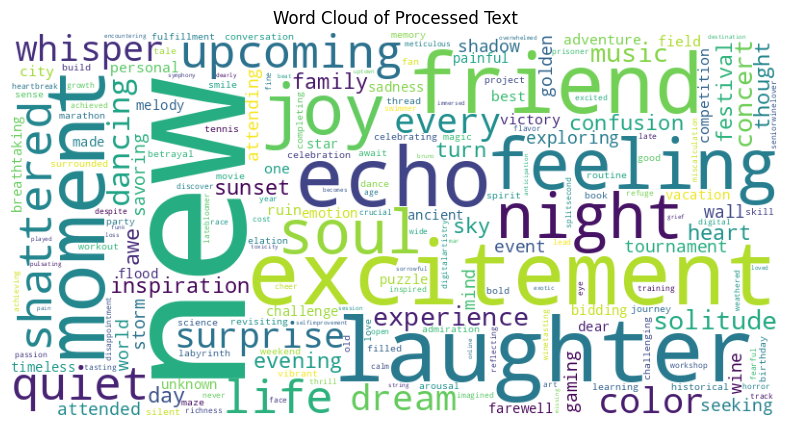

In [ ]:
text_all = " ".join(all_words)

word_cloud = WordCloud(
    width=800,
    height=400,
    background_color="white"
).generate(text_all)

plt.figure(figsize=(10, 5))
plt.imshow(word_cloud)
plt.axis("off")
plt.title("Word Cloud of Processed Text")
plt.show()